# 04 · Comparación supervisado vs no supervisado y conclusiones
Reunimos los resultados de los notebooks 02 (supervisado) y 03 (no supervisado), los comparamos y respondemos las preguntas de comparación.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RAIZ = Path("..").resolve()            # raíz del repositorio
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp

DATA_DIR = RAIZ / "data" / "raw"       # CSV originales
PROC_DIR = RAIZ / "data" / "processed" # muestra dividida (del notebook 01)
RES_DIR = RAIZ / "resultados"          # métricas en JSON
SEED = 42
N_MUESTRA = int(os.environ.get("N_MUESTRA", 150_000))

In [2]:
sup = json.loads((RES_DIR / "supervisado.json").read_text(encoding="utf-8"))
nos = json.loads((RES_DIR / "no_supervisado.json").read_text(encoding="utf-8"))
tabla = pd.DataFrame(sup["modelos"]).T[["pr_auc", "roc_auc", "precision", "recall", "f1", "costo"]]
tabla.loc["Isolation Forest (sin etiqueta)", ["pr_auc", "roc_auc"]] = [nos["isolation_forest"]["pr_auc"], nos["isolation_forest"]["roc_auc"]]
display(tabla.round(3))
print("Prevalencia de fraude en prueba (PR-AUC del azar):", round(sup["prevalencia_test"], 4))

,pr_auc,roc_auc,precision,recall,f1,costo
Regresión logística,0.216,0.821,0.388,0.295,0.335,12195.0
Gradient Boosting sin pesos,0.475,0.868,0.652,0.369,0.471,10559.0
Gradient Boosting con pesos,0.470,0.866,0.651,0.379,0.479,10399.0
Gradient Boosting ajustado,0.481,0.873,0.583,0.392,0.469,10315.0
Isolation Forest (sin etiqueta),0.119,0.752,NaN,NaN,NaN,NaN


Prevalencia de fraude en prueba (PR-AUC del azar): 0.036


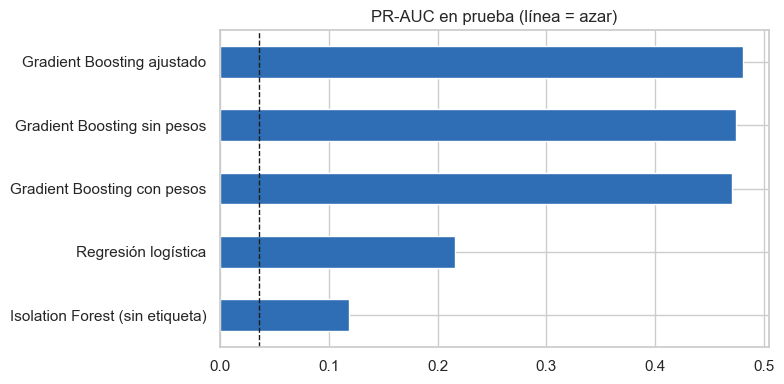

Mejor modelo supervisado: Gradient Boosting ajustado
Variables más importantes: ['C1', 'C13', 'TransactionAmt', 'card6', 'V318']


In [3]:
ax = tabla["pr_auc"].dropna().sort_values().plot(kind="barh", figsize=(8, 4), color="#2F6DB5")
ax.axvline(sup["prevalencia_test"], color="k", ls="--", lw=1); ax.set_title("PR-AUC en prueba (línea = azar)")
plt.tight_layout(); plt.show()
print("Mejor modelo supervisado:", sup["mejor_modelo"])
print("Variables más importantes:", list(sup["top_variables"])[:5])

## Preguntas de comparación entre los dos enfoques

**1. ¿Qué problema busca resolver cada componente?**
- *Supervisado:* estimar la probabilidad de que una transacción sea fraude, aprendiendo de transacciones pasadas cuya etiqueta (`isFraud`) ya se conoce.
- *No supervisado:* encontrar estructura en las transacciones sin usar la etiqueta —tipos de transacción y casos atípicos— y ver después si eso tiene relación con el fraude.

**2. ¿Qué algoritmos se eligieron y por qué son apropiados?**
- *Supervisado:* regresión logística como punto de partida simple y explicable, y Gradient Boosting porque funciona muy bien con datos tabulares, captura relaciones no lineales y tolera los muchos valores vacíos. Lo comparamos con y sin pesos de clase por el desbalance.
- *No supervisado:* K-Means y mezcla gaussiana para agrupar (la segunda es más flexible), e Isolation Forest para ordenar las transacciones por rareza, porque el fraude es poco frecuente y podría verse distinto del resto.

**3. ¿Qué dificultades se presentaron?**
- Desbalance fuerte: 1 fraude por cada 28 transacciones.
- Muchos faltantes (229 de 437 columnas con más de la mitad vacía) y variables con muchas categorías (`DeviceInfo` con 997).
- Tamaño del dataset: 590.540 filas y 434 columnas, por lo que trabajamos con una muestra de 150.000 y el cómputo tarda (el ajuste de hiperparámetros, 15 a 20 minutos).
- Valores extremos en variables anónimas (hasta 324 desviaciones estándar), que arruinaban el agrupamiento hasta que los recortamos.
- El fraude cambia con el tiempo: el PR-AUC fue 0,54 en validación y 0,48 en prueba.

**4. ¿El supervisado identificó los casos de interés? ¿Qué métricas lo respaldan?**
Sí, con límites. El mejor modelo (Gradient Boosting ajustado) logra PR-AUC de 0,481 contra 0,036 del azar (unas 13 veces mejor) y ROC-AUC de 0,873. Con el umbral que maximiza F1, de cada 10 alertas unas 6 son fraude (precision 0,58) y se detectan unos 4 de cada 10 fraudes (recall 0,39). Si se prioriza no dejar pasar fraudes, el recall sube a 0,64 a cambio de una precision de 0,25.

**5. ¿El no supervisado descubrió estructuras no evidentes?**
Parcialmente. Encontró dos tipos de transacción bien marcados —un grupo pequeño de producto C con montos bajos y uno grande de producto W con montos altos—, pero la separación es débil (silhouette de 0,30). No son estructuras ocultas sorprendentes: coinciden con lo que ya se veía en el análisis exploratorio.

**6. ¿Qué relación hay entre las etiquetas y los grupos encontrados?**
El grupo pequeño del producto C tiene 13,2 % de fraude, unas 3,7 veces el promedio (3,6 %), y el grande 2,5 %. El Isolation Forest, sin ver nunca una etiqueta, logra ROC-AUC de 0,75 y PR-AUC de 0,12 (unas 3 veces el azar): el 21 % de las transacciones que marca como más raras (el 3 %) son fraude. Es decir, lo atípico tiene más probabilidad de ser fraude, pero no todo lo atípico lo es y no todo el fraude es atípico.

**7. ¿Qué información se conserva o se pierde con la reducción de dimensionalidad?**
Con 86 componentes se conserva el 90 % de la varianza de las 398 columnas, lo que muestra mucha redundancia. Pero las dos componentes que se dibujan conservan solo el 19 %, así que los gráficos en 2D muestran una parte pequeña de la estructura y t-SNE, aunque ayuda a ver vecindades, distorsiona las distancias.

**8. ¿Qué enfoque recomendaría el grupo para una aplicación real?**
Usar el modelo supervisado como detector principal, con un umbral elegido según el costo real de cada tipo de error, y el Isolation Forest como complemento para señalar casos raros que merezcan revisión y para detectar patrones nuevos, ya que no depende de etiquetas. El supervisado es mucho más preciso (PR-AUC de 0,48 contra 0,12), pero solo aprende fraudes que ya conoce y necesita etiquetas confiables; el no supervisado es peor, pero puede avisar de algo distinto. Además, hay que reentrenar con frecuencia porque el fraude cambia con el tiempo.

## Conclusiones y recomendaciones
1. **Hallazgo del análisis exploratorio:** el fraude es raro (3,5 %) y se concentra en ciertos productos, tipos de tarjeta, dispositivos y correos; el monto casi no lo distingue y tener datos de identidad se asocia con más fraude.
2. **Supervisado:** Gradient Boosting ajustado logra PR-AUC de 0,481, unas 13 veces el azar, con precision 0,58 y recall 0,39. La regresión logística queda muy atrás (0,216). Los pesos de clase y el ajuste de hiperparámetros casi no cambiaron el resultado.
3. **No supervisado:** hay dos tipos de transacción (producto C contra producto W) con separación débil; el grupo del producto C tiene 3,7 veces más fraude que el promedio. El Isolation Forest, sin etiquetas, logra PR-AUC de 0,12 (unas 3 veces el azar).
4. **Cómo se complementan:** el supervisado detecta mejor lo ya conocido, pero necesita etiquetas; el no supervisado no las necesita y puede alertar sobre comportamientos nuevos, aunque con mucho menos precisión.
5. **Recomendación y costo de los errores:** un fraude que pasa cuesta más que revisar una transacción legítima. Con el supuesto de 10 a 1, el umbral que minimiza el costo detecta el 64 % de los fraudes y baja el costo total cerca de un 12 %, a cambio de más falsos positivos (3.167 contra 455). El costo real debe estimarlo cada negocio.
6. **Limitaciones y trabajo futuro:** usamos una muestra de 150.000 transacciones; probar con todas las transacciones y con variables por cliente mejoró poco (PR-AUC de unos 0,5); muchas variables son anónimas; el costo de 10 a 1 es un supuesto; y el fraude cambia con el tiempo, por lo que habría que reentrenar y vigilar el desempeño.